### Did by Halim NJEIM and Riccardo VENTURINI

# Lab 2: Deep Learning Mini-Project: Image Quality Assessment

Authors: Alexandre Bruckert, Nantes Université

Date: 2026/2027

Over the next two lab sessions (6 hours), you will transition from learning basic PyTorch syntax to designing, optimizing, and evaluating neural networks for a real-world task.

## The task: Image Quality Assessment (IQA)

Instead of classifying what is in an image, you will predict how good it looks.
You are tackling an Image Quality Assessment (IQA) task. Your model will analyze an image and predict its Mean Opinion Score (MOS), which is a continuous value usually ranging from 1.0 (terrible quality) to 5.0 (excellent quality), representing the average human perception of the image's visual appeal, sharpness, and lack of distortions.

Because the target is a continuous number, this is a **regression** problem.

## The Dataset: KonIQ-10k
For this challenge, you will be working with the **KonIQ-10k** dataset, a major benchmark in the field of Image Quality Assessment. It consists of 10,073 images carefully sampled from a massive public multimedia database. Unlike older academic datasets where pristine images were artificially corrupted with math-generated noise, KonIQ-10k features **"in-the-wild" authentic distortions**. This means the images suffer from real-world, everyday issues: poor lighting, shaky hands (motion blur), cheap camera sensors, and aggressive JPEG compression. The ground truth MOS labels (ranging from 1.0 to 5.0) were collected through a massive crowdsourcing effort involving over 1.2 million human ratings.

The KonIQ-10k dataset is available at: https://database.mmsp-kn.de/koniq-10k-database.html
You should use the lower resolution images ($512 \times 384$) for this work.

## Evaluation

You are tasked with building the best model possible for this task. You will be evaluated based on a **heavily documented** notebook that contains your code, results, and analysis. The notebook should be structured to clearly present your approach, experiments, and findings.

Your notebook must contain the following distinct sections, representing "milestones" in the project:

- Milestone 1: The CNN Baseline: Design and train a Convolutional Neural Network (CNN) using MSELoss.

- Milestone 2: The RNN Experiment: Treat the image as a sequence of pixel rows! Design a Recurrent Neural Network (LSTM or GRU) to predict the MOS. Compare its performance to the CNN.

- Milestone 3: The Transfer Learning Approach: Use a pre-trained model (e.g., ResNet, EfficientNet) as a feature extractor. Fine-tune it for the IQA task and compare its performance to your previous models.

- Milestone 4: The Ultimate Model: Combine Early Stopping, Schedulers, Regularization, and your best architecture to build your final model.

Similarly to the grid in Lab 1, the concepts explored in each milestone will be part of the program of the final exam!

## 1. Setup

Here below, you will find the necessary imports and a custom Dataset class to load the KonIQ-10k dataset. You will need to download the dataset and place it in a folder named `iqa_data` with the following structure:
```
iqa_data/
├── images/
├── train_labels.csv
```

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
set_seed(42)

# ====================================================================
# 1. CUSTOM DATASET CLASS (Provided)
# ====================================================================
# In real-world projects, data doesn't come neatly packaged in PyTorch.
# You have a folder of images and a CSV file with labels.
# We build a custom Dataset class to handle this.

class IQADataset(Dataset):
    def __init__(self, csv_file, img_dir, transform=None):
        """
        Args:
            csv_file (string): Path to the csv file with annotations (columns: image_id, mos).
            img_dir (string): Directory with all the images.
            transform (callable, optional): Optional transform to be applied on a sample.
        """
        # Load the CSV file
        self.labels_df = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.labels_df)

    def __getitem__(self, idx):
        # Get image name and target MOS
        img_name = str(self.labels_df.iloc[idx]['image_name'])
        mos = float(self.labels_df.iloc[idx]['MOS'])

        # Load image from disk
        img_path = os.path.join(self.img_dir, img_name)
        image = Image.open(img_path).convert('RGB')

        # Apply transformations (e.g., resizing, converting to tensor)
        if self.transform:
            image = self.transform(image)

        # Return the image and the MOS (as a float32 tensor for regression)
        return image, torch.tensor(mos, dtype=torch.float32)

# ====================================================================
# DATA LOADING EXAMPLE
# ====================================================================
# Resize all images to 128x128 to keep training relatively fast
base_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Assuming you have downloaded the dataset into a folder named 'iqa_data'
# containing 'images/' folder and 'train_labels.csv'
#
dataset = IQADataset(csv_file='iqa_data/train_labels.csv',
                      img_dir='iqa_data/images',
                      transform=base_transform)

sample, label = dataset[0]
print(f"Sample {0}: {sample}")
print(f"Label {0}: {label}")

print("Dataset class ready! Your turn to instantiate it and create DataLoaders.")

Using device: cpu
Sample 0: tensor([[[ 0.2706, -0.3647, -0.4039,  ..., -0.6157, -0.6471, -0.6078],
         [-0.3490, -0.5216, -0.2784,  ..., -0.8667, -0.8588, -0.8824],
         [-0.8980, -0.8824, -0.7725,  ..., -0.9216, -0.8431, -0.7647],
         ...,
         [-0.4980, -0.5686, -0.2392,  ..., -0.7725, -0.9137, -0.8824],
         [-0.5451, -0.5529, -0.4980,  ..., -0.7804, -0.9294, -0.9137],
         [-0.3569, -0.3647, -0.4980,  ..., -0.8353, -0.9294, -0.9294]],

        [[ 0.3176, -0.2863, -0.3412,  ..., -0.3333, -0.4353, -0.3882],
         [-0.1922, -0.3647, -0.1686,  ..., -0.7725, -0.7804, -0.8353],
         [-0.7882, -0.7804, -0.6549,  ..., -0.9373, -0.8196, -0.7176],
         ...,
         [-0.3176, -0.4667, -0.1294,  ..., -0.6784, -0.8824, -0.8667],
         [-0.3490, -0.3882, -0.3176,  ..., -0.7020, -0.9059, -0.8980],
         [-0.1765, -0.2078, -0.3098,  ..., -0.7882, -0.9059, -0.9137]],

        [[ 0.3804, -0.2471, -0.2784,  ..., -0.0510, -0.3255, -0.3490],
         [-0.2157

# Milestone 1


Train : 8058 | Val : 2015

--- 3. Creating DataLoaders ---

--- 4. Batch Visualization ---


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5764706..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.94509804..0.99215686].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


Shape of an image batch : torch.Size([24, 3, 128, 128])


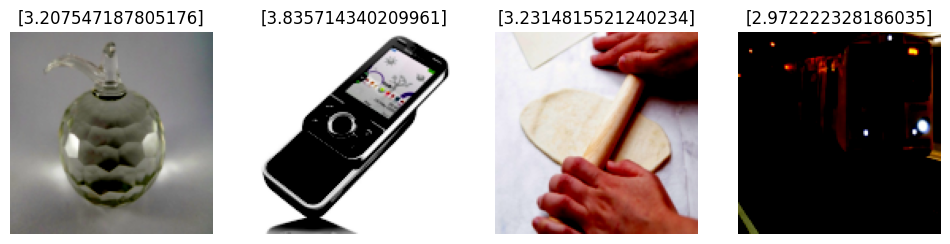

In [35]:
generator = torch.Generator().manual_seed(123)

# TODO : Divide raw_dataset into train_dataset (80%) and val_dataset (20%)
# train_dataset, val_dataset = ...
train_size = int(0.8 * len(dataset))
val_size = int(len(dataset) - train_size)

train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

print(f"Train : {len(train_dataset)} | Val : {len(val_dataset)}")

print("\n--- 3. Creating DataLoaders ---")
# The batch_size is a hyperparameter that controls the size of the batches (i.e. how many images are fed to the model at each iteration).
batch_size = 24

# TODO : Create the corresponding DataLoaders.
# IMPORTANT : it is particularly important to shuffle (arg. shuffle=True) the train_loader
# in order to avoid having the model memorizing the order of the images.
# This is not necessary for the validation and test loaders.
# train_loader = ...
# val_loader = ...
# test_loader = ...
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=True
)



print("\n--- 4. Batch Visualization ---")

images, labels = next(iter(train_loader))

print(f"Shape of an image batch : {images.shape}")



fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i in range(4):
    
    img = images[i].squeeze().permute(1,2,0)
    axes[i].set_title([labels[i].item()])

    axes[i].imshow(img)
    axes[i].axis('off')
plt.show()


In [9]:

import torch.nn as nn


class CNN(nn.Module):
    def __init__(self, input_channels=3, image_size=128,conv_channels=[32, 64, 128], hidden_sizes=[256, 128], dropout_rate=0.0, score_min=1.0, score_max=5.0,
    ):
        """
        CNN for image quality regression.

        :param input_channels: Number of image channels (3 for RGB, 1 for grayscale).
        :param image_size: Spatial size of the square input image, e.g. 128.
        :param conv_channels: Number of filters in each convolutional block.
        :param hidden_sizes: Number of neurons in each fully connected hidden layer.
        :param dropout_rate: Dropout probability.
        :param score_min: Minimum possible rating.
        :param score_max: Maximum possible rating.
        """
        super(CNN, self).__init__()

        self.score_min = score_min
        self.score_max = score_max

        # ----- Convolutional feature extractor -----
        conv_layers = []
        in_channels = input_channels

        for out_channels in conv_channels:
            conv_layers.extend([
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2, stride=2),
                nn.Dropout2d(dropout_rate),
            ])
            in_channels = out_channels

        self.features = nn.Sequential(*conv_layers)

        # ----- Compute flattened feature size dynamically -----
        # With 3 MaxPool layers: 128 -> 64 -> 32 -> 16
        feature_map_size = image_size // (2 ** len(conv_channels))
        flattened_size = conv_channels[-1] * feature_map_size * feature_map_size

        # ----- Fully connected regression head -----
        fc_layers = []
        in_features = flattened_size

        for hidden_size in hidden_sizes:
            fc_layers.extend([
                nn.Linear(in_features, hidden_size),
                nn.BatchNorm1d(hidden_size),
                nn.ReLU(),
                nn.Dropout(dropout_rate),
            ])
            in_features = hidden_size

        # Final regression layer: exactly one output, no activation
        fc_layers.append(nn.Linear(in_features, 1))

        self.classifier = nn.Sequential(*fc_layers)

    def forward(self, x):
        """
        :param x: Tensor of shape [batch_size, channels, height, width]
        :return: Tensor of shape [batch_size] containing scores in [1.0, 5.0]
        """
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)

        # Shape [batch_size, 1] -> [batch_size]
        x = x.squeeze(1)

        # Optional: constrain prediction to the valid rating range
        x = self.score_min + (self.score_max - self.score_min) * torch.sigmoid(x)

        return x


### Model Training

In [10]:
import torch.optim as optim

# Good practice: Code should be agnostic to the device (allows for CPU, CUDA, or MPS usage).
# We will use the device variable to move our model and data to the appropriate device.
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device : {device}")

def train_epoch(model, dataloader, criterion, optimizer, device):
    """
    Trains a PyTorch model for one complete epoch using provided data, loss
    function, and optimizer. Keeps track of accumulated loss and accuracy
    metrics across the epoch and returns these values.

    :param model: (torch.nn.Module) PyTorch model to be trained.
    :param dataloader: (torch.utils.data.Dataloader) Iterable DataLoader object providing batches of
                       input data and corresponding labels.
    :param criterion: (torch.nn.Module) Loss function used for training the model.
    :param optimizer: (torch.optim.Optimizer) The optimization algorithm to update model parameters.
    :param device: (torch.device) The device on which computation is performed (e.g., 'cpu'
                   or 'cuda').

    :return: (tuple[float,float]) Tuple containing the normalized loss and accuracy for the
             epoch.
    """
    model.train() # Set model to training mode (enables Dropout, etc.)
    running_loss = 0.0
    running_abs_error = 0.0
    total = 0

    for inputs, labels in dataloader:
        # Move data to the same device as the model (CPU or GPU)
        inputs, labels = inputs.to(device), labels.to(device)

        # TODO: Implement the 5 golden steps of PyTorch training
        # 1. Zero the gradients
        # optimizer...
        optimizer.zero_grad()
        
        # 2. Forward pass
        # outputs = ...
        outputs = model(inputs)
        
        # 3. Compute the loss
        # loss = ...
        loss = criterion(outputs, labels)
        
        # 4. Backward pass
        # loss...
        loss.backward()
        
        # 5. Optimizer step
        # optimizer...
        optimizer.step()
        
        # --- Metrics Calculation ---
        # TODO: Get the predicted class (the index of the highest probability)
        # preds = ...
        batch_size = labels.size(0)
        # Update statistics
        running_loss += loss.item() * batch_size
        running_abs_error += torch.abs(outputs - labels).sum().item()
        total += batch_size

    epoch_loss = running_loss / total
    epoch_mae = running_abs_error / total
    return epoch_loss, epoch_mae

def validation(model, dataloader, criterion, device):
    """
    Evaluates a given model using a provided dataloader and criterion, and computes
    the average loss and accuracy over the evaluation dataset.

    :param model: (torch.nn.Module) Neural network model to be evaluated.
    :param dataloader: (torch.utils.data.Dataloader) Iterable over the dataset for evaluation, providing input
        data and associated labels in mini-batches.
    :param criterion: (torch.nn.Module) Loss function used to compute the evaluation loss.
    :param device: (torch.device) Device (CPU or GPU) where computations will be performed.

    :return: (tuple[float, float]) Tuple containing the average loss and accuracy over the validation
        dataset.
    """
    model.eval() # Set model to evaluation mode (disables Dropout)
    running_loss = 0.0
    running_abs_error = 0.0
    total = 0

    # We don't need gradients for validation, so we wrap it in no_grad
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)

            # TODO: Perform the forward pass and compute the loss
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            

            # TODO: Get the predictions and update statistics
            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            running_abs_error += torch.abs(outputs - labels).sum().item()
            total += batch_size

    epoch_loss = running_loss / total
    epoch_mae = running_abs_error / total
    return epoch_loss, epoch_mae

Device : cpu


In [11]:
# Let's create an instance of our CNN model and print it to check its structure
model = CNN( input_channels=3, image_size=128, conv_channels=[32, 64, 128], hidden_sizes=[128], dropout_rate=0.2, score_min=1.0, score_max=5.0,
)

print(model)


# Sanity check: Pass a dummy batch through the untrained model
dummy_input = torch.randn(16, 3, 128, 128)  # Batch of 16 RGB images
dummy_output = model(dummy_input)

print(f"Input shape: {dummy_input.shape}")
print(f"Output shape (should be [16]): {dummy_output.shape}")
print(f"Output dtype: {dummy_output.dtype}")
print(f"Output range (should be within [1.0, 5.0]): "
      f"[{dummy_output.min().item():.4f}, {dummy_output.max().item():.4f}]")

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.2, inplace=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout2d(p=0.2, inplace=False)
    (10): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Dropout2d(p=0.2, inplace=False)
  )
  (classifi

In [12]:
# MAIN EXECUTION

# 1. Initialize the model, loss function, and optimizer
# We use the device defined in Part 1 (CPU, CUDA, or MPS)
model = CNN(
    input_channels=3,          # Use 1 for grayscale images
    image_size=128,
    conv_channels=[32, 64, 128],
    hidden_sizes=[128],
    dropout_rate=0.2,
    score_min=1.0,
    score_max=5.0,
).to(device)


# MSELoss is used because this is a regression task:
# the model predicts a continuous rating between 1.0 and 5.0.
criterion = nn.MSELoss()


# Adam is a robust, adaptive learning-rate optimizer.
optimizer = optim.Adam(model.parameters(), lr=1e-3)


# 2. The Main Loop
epochs = 15
history = {
    'train_loss': [],
    'val_loss': [],
    'train_mae': [],
    'val_mae': [],
}

best_val_loss = float("inf")

print("Starting training...")
for epoch in range(epochs):
    # Train and evaluate
    train_loss, train_mae = train_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_mae = validation(
        model, val_loader, criterion, device
    )

    # Save metrics for plotting later
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_mae'].append(train_mae)
    history['val_mae'].append(val_mae)
    
    #Save best model 
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_cnn_rating_model.pth")

    # Print progress
    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train MSE: {train_loss:.4f} - MAE: {train_mae:.4f} | "
        f"Val MSE: {val_loss:.4f} - MAE: {val_mae:.4f}"
    )

Starting training...
Epoch [1/15] | Train MSE: 0.2768 - MAE: 0.4125 | Val MSE: 0.2123 - MAE: 0.3736
Epoch [2/15] | Train MSE: 0.2292 - MAE: 0.3755 | Val MSE: 0.2073 - MAE: 0.3698
Epoch [3/15] | Train MSE: 0.2135 - MAE: 0.3619 | Val MSE: 0.2040 - MAE: 0.3518
Epoch [4/15] | Train MSE: 0.2101 - MAE: 0.3584 | Val MSE: 0.1892 - MAE: 0.3432
Epoch [5/15] | Train MSE: 0.2034 - MAE: 0.3514 | Val MSE: 0.1868 - MAE: 0.3399
Epoch [6/15] | Train MSE: 0.2028 - MAE: 0.3505 | Val MSE: 0.1906 - MAE: 0.3375
Epoch [7/15] | Train MSE: 0.1998 - MAE: 0.3495 | Val MSE: 0.1799 - MAE: 0.3341
Epoch [8/15] | Train MSE: 0.1960 - MAE: 0.3451 | Val MSE: 0.1823 - MAE: 0.3329
Epoch [9/15] | Train MSE: 0.1931 - MAE: 0.3408 | Val MSE: 0.1813 - MAE: 0.3326
Epoch [10/15] | Train MSE: 0.1878 - MAE: 0.3375 | Val MSE: 0.1858 - MAE: 0.3429
Epoch [11/15] | Train MSE: 0.1849 - MAE: 0.3342 | Val MSE: 0.1821 - MAE: 0.3370
Epoch [12/15] | Train MSE: 0.1815 - MAE: 0.3305 | Val MSE: 0.1861 - MAE: 0.3492
Epoch [13/15] | Train MSE: 0

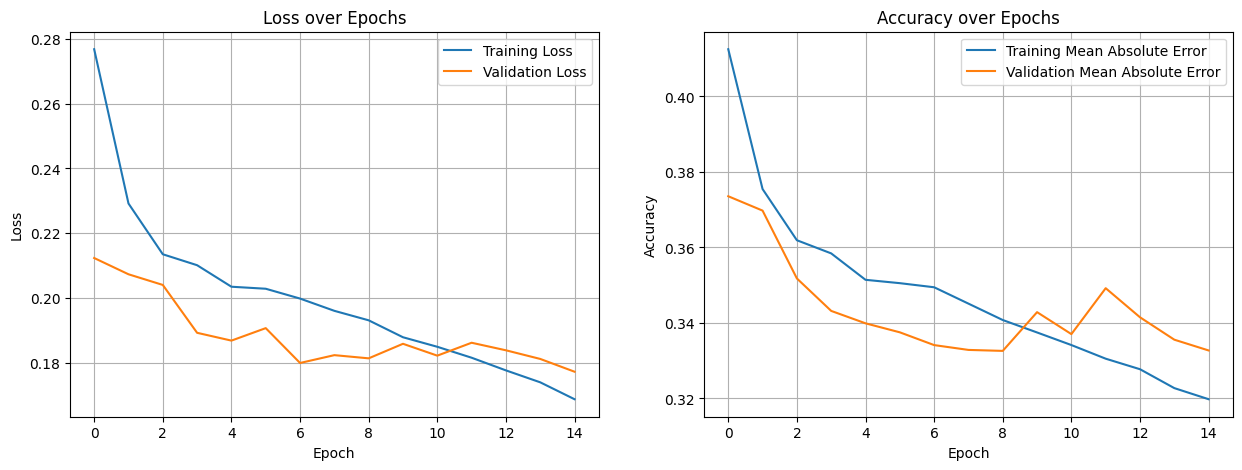

In [14]:
import matplotlib.pyplot as plt

# 1. Plotting the Learning Curves
# We will create a figure with two subplots: one for Loss, one for Accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# TODO: Plot Train Loss and Validation Loss on the first axis (ax1)
# Use history['train_loss'] and history['val_loss']
# ax1.plot(...)
# ax1.plot(...)
ax1.plot(range( epochs), history['train_loss'], label = 'Training Loss')
ax1.plot(range( epochs), history["val_loss"], label = "Validation Loss")
ax1.set_title('Loss over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# TODO: Plot Train Accuracy and Validation Accuracy on the second axis (ax2)
# Use history['train_acc'] and history['val_acc']
# ax2.plot(...)
# ax2.plot(...)
ax2.plot(range( epochs), history['train_mae'], label = 'Training Mean Absolute Error')
ax2.plot(range( epochs), history['val_mae'], label = 'Validation Mean Absolute Error')

ax2.set_title('Accuracy over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.show()

## MAE is the mean absolute error. That is how far the model's predicted score is from the actual rating of the images we are passing in the batches.

## RNN Design and Training.

### Key differences:

The RNN model is very similar to the CNN model, as both use ReLU as activation function for the neurons, both use MSELoss function, Adam optimizer and both output the same continuous score to rate the image quality.

The main difference is how they extract the feature; how they treat the image. The CNN model treats the image as it is, a 2D grid of pixels on which filters are applied to extract features through the convolutional layers. While in RNN, the image is treated as a sequence of rows, each row built from the 128 horiztonally aligned pixels of the image.

Within the CNN, ReLU is used after each convolutional block. ReLU is an activation function that outputs linear values. Meaning it inputs the output directly as it is if is positive, but 0 if the output of a neuron was negative. The benefit of such function is that it is light computationally. It helps with backpropagation and learning of the deep layers of a network.

In the RNN, we chose to use GRU. While LSTM would have equally worked for the task, GRUs are slightly lighter to train and experiment with.
It is true that an LTSM would have given superior results in this task considering the long sequence of the rows of pixels (128 rows x 3 channels), but all in all a CNN could do a better job with much less resources, considering image quality rating does not depend on a 3rd dimension (time) for which RNNs are better suited.

Because RNN loses much information in-between the inputs and the outputs and needs many connections for it to become adequate for the task as was shown in our results. A CNN model with almost the same parameters outperformed the RNN dramatically.

In [15]:
import torch
import torch.nn as nn


class ImageRowGRU(nn.Module):
    def __init__(
        self,
        image_size=128,
        input_channels=3,
        hidden_size=128,
        num_layers=2,
        fc_hidden_size=64,
        dropout_rate=0.2,
        bidirectional=True,
        score_min=1.0,
        score_max=5.0,
    ):
        """
        GRU-based image quality regression model.

        Treats each image as a sequence of pixel rows:
            [batch_size, channels, height, width]
                -> [batch_size, height, channels * width]

        :param image_size: Height/width of the square input image.
        :param input_channels: Number of image channels (3 for RGB).
        :param hidden_size: Number of GRU hidden units.
        :param num_layers: Number of stacked GRU layers.
        :param fc_hidden_size: Size of the fully connected hidden layer.
        :param dropout_rate: Dropout probability.
        :param bidirectional: If True, processes rows from top-to-bottom and bottom-to-top.
        :param score_min: Minimum MOS value.
        :param score_max: Maximum MOS value.
        """
        super(ImageRowGRU, self).__init__()

        self.image_size = image_size
        self.input_channels = input_channels
        self.score_min = score_min
        self.score_max = score_max

        # Each pixel row is one time step.
        # For RGB: each row has 3 * 128 = 384 features.
        self.input_size = input_channels * image_size
        self.sequence_length = image_size

        self.gru = nn.GRU(
            input_size=self.input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout_rate if num_layers > 1 else 0.0,
            bidirectional=bidirectional,
        )

        gru_output_size = hidden_size * 2 if bidirectional else hidden_size

        self.regressor = nn.Sequential(
            nn.Linear(gru_output_size, fc_hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(fc_hidden_size, 1),
        )

    def forward(self, x):
        """
        :param x: Tensor of shape [batch_size, channels, height, width]
        :return: Tensor of shape [batch_size], with values in [score_min, score_max]
        """
        batch_size = x.size(0)

        # [B, C, H, W] -> [B, H, C, W]
        x = x.permute(0, 2, 1, 3)

        # [B, H, C, W] -> [B, H, C * W]
        x = x.reshape(batch_size, self.sequence_length, self.input_size)

        # GRU input: [batch_size, sequence_length, input_size]
        gru_out, _ = self.gru(x)

        # Use the final hidden state as a summary of the whole image.
        # gru_out shape: [batch_size, sequence_length, hidden_size * directions]
        image_embedding = gru_out[:, -1, :]

        # Predict one continuous MOS score.
        score = self.regressor(image_embedding)

        # [batch_size, 1] -> [batch_size]
        score = score.squeeze(1)

        # Map the unbounded GRU/linear output into [1, 5].
        score = self.score_min + (self.score_max - self.score_min) * torch.sigmoid(score)

        return score

In [16]:
import torch.optim as optim


def train_epoch(model, dataloader, criterion, optimizer, device):
    """
    Trains the GRU regression model for one epoch.

    :return: (epoch_mse_loss, epoch_mae)
    """
    model.train()

    running_loss = 0.0
    running_abs_error = 0.0
    total = 0

    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Ensure labels match the model output shape [batch_size].
        labels = labels.float().view(-1)

        # 1. Zero gradients from the previous batch
        optimizer.zero_grad()

        # 2. Forward pass
        outputs = model(inputs)  # shape: [batch_size]

        # 3. Compute regression loss
        loss = criterion(outputs, labels)

        # 4. Backpropagate
        loss.backward()

        # Optional but useful for RNNs: prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        # 5. Update parameters
        optimizer.step()

        # Metrics
        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        running_abs_error += torch.abs(outputs - labels).sum().item()
        total += batch_size

    epoch_loss = running_loss / total
    epoch_mae = running_abs_error / total

    return epoch_loss, epoch_mae


def validation(model, dataloader, criterion, device):
    """
    Evaluates the GRU regression model.

    :return: (epoch_mse_loss, epoch_mae)
    """
    model.eval()

    running_loss = 0.0
    running_abs_error = 0.0
    total = 0

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            labels = labels.float().view(-1)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            running_abs_error += torch.abs(outputs - labels).sum().item()
            total += batch_size

    epoch_loss = running_loss / total
    epoch_mae = running_abs_error / total

    return epoch_loss, epoch_mae

In [17]:
# Create the GRU model
model = ImageRowGRU(
    image_size=128,
    input_channels=3,
    hidden_size=128,
    num_layers=2,
    fc_hidden_size=64,
    dropout_rate=0.2,
    bidirectional=True,
).to(device)

print(model)

# Dummy batch: 16 RGB images of size 128 x 128
dummy_input = torch.randn(16, 3, 128, 128).to(device)
dummy_output = model(dummy_input)

print(f"Input shape: {dummy_input.shape}")
print(f"Output shape (should be [16]): {dummy_output.shape}")
print(f"Output dtype: {dummy_output.dtype}")
print(
    f"Output range (should be within [1.0, 5.0]): "
    f"[{dummy_output.min().item():.4f}, {dummy_output.max().item():.4f}]"
)

# Check compatibility with MSELoss
criterion = nn.MSELoss()
dummy_labels = torch.rand(16, device=device) * 4 + 1  # ratings in [1, 5]
dummy_loss = criterion(dummy_output, dummy_labels)

print(f"Dummy MSE loss: {dummy_loss.item():.4f}")

ImageRowGRU(
  (gru): GRU(384, 128, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (regressor): Sequential(
    (0): Linear(in_features=256, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
Input shape: torch.Size([16, 3, 128, 128])
Output shape (should be [16]): torch.Size([16])
Output dtype: torch.float32
Output range (should be within [1.0, 5.0]): [2.9558, 3.1130]
Dummy MSE loss: 1.5943


In [18]:
# MAIN EXECUTION

# 1. Initialize model, loss, and optimizer
model = ImageRowGRU(
    image_size=128,
    input_channels=3,
    hidden_size=128,
    num_layers=2,
    fc_hidden_size=64,
    dropout_rate=0.2,
    bidirectional=True,
).to(device)

# Regression loss: mean squared error between predicted and true MOS
criterion = nn.MSELoss()

optimizer = optim.Adam(model.parameters(), lr=1e-3)

# 2. Training loop
epochs = 15

history = {
    'train_loss': [],
    'val_loss': [],
    'train_mae': [],
    'val_mae': [],
}

best_val_loss = float("inf")

print("Starting training...")
for epoch in range(epochs):
    train_loss, train_mae = train_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_mae = validation(
        model, val_loader, criterion, device
    )

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_mae'].append(train_mae)
    history['val_mae'].append(val_mae)

    # Save the best model according to validation MSE
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_image_row_gru_model.pth")

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train MSE: {train_loss:.4f} - MAE: {train_mae:.4f} | "
        f"Val MSE: {val_loss:.4f} - MAE: {val_mae:.4f}"
    )

Starting training...
Epoch [1/15] | Train MSE: 0.2772 - MAE: 0.4183 | Val MSE: 0.2520 - MAE: 0.4001
Epoch [2/15] | Train MSE: 0.2503 - MAE: 0.3925 | Val MSE: 0.2449 - MAE: 0.3824
Epoch [3/15] | Train MSE: 0.2403 - MAE: 0.3826 | Val MSE: 0.2320 - MAE: 0.3864
Epoch [4/15] | Train MSE: 0.2337 - MAE: 0.3760 | Val MSE: 0.2315 - MAE: 0.3792
Epoch [5/15] | Train MSE: 0.2262 - MAE: 0.3696 | Val MSE: 0.2345 - MAE: 0.3844
Epoch [6/15] | Train MSE: 0.2212 - MAE: 0.3652 | Val MSE: 0.2271 - MAE: 0.3826
Epoch [7/15] | Train MSE: 0.2135 - MAE: 0.3561 | Val MSE: 0.2238 - MAE: 0.3719
Epoch [8/15] | Train MSE: 0.2038 - MAE: 0.3490 | Val MSE: 0.2331 - MAE: 0.3860
Epoch [9/15] | Train MSE: 0.1949 - MAE: 0.3391 | Val MSE: 0.2278 - MAE: 0.3736
Epoch [10/15] | Train MSE: 0.1862 - MAE: 0.3320 | Val MSE: 0.2428 - MAE: 0.3991
Epoch [11/15] | Train MSE: 0.1733 - MAE: 0.3181 | Val MSE: 0.2453 - MAE: 0.3883
Epoch [12/15] | Train MSE: 0.1644 - MAE: 0.3103 | Val MSE: 0.2382 - MAE: 0.3819
Epoch [13/15] | Train MSE: 0

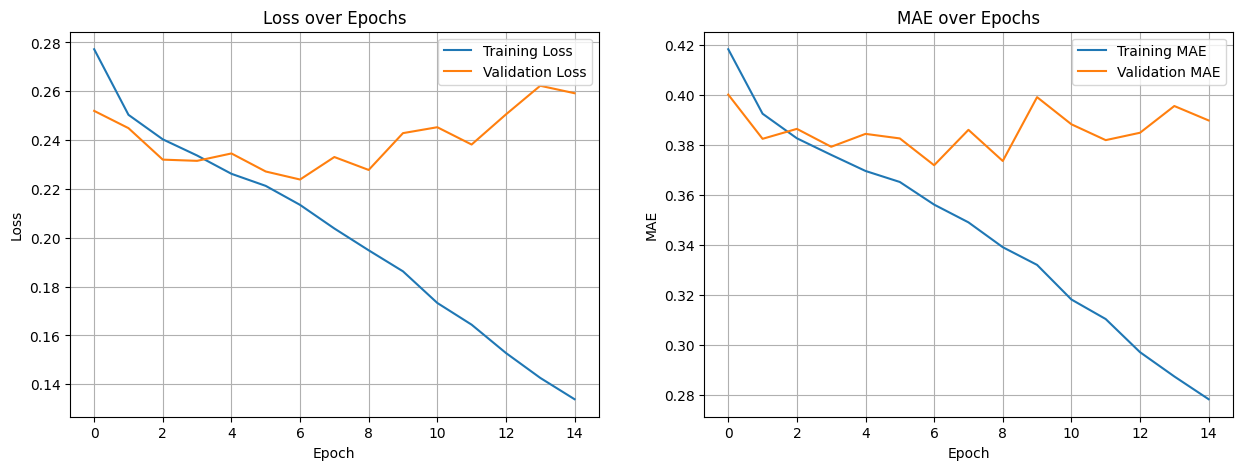

In [19]:
import matplotlib.pyplot as plt

# 1. Plotting the Learning Curves
# We will create a figure with two subplots: one for Loss, one for Accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# TODO: Plot Train Loss and Validation Loss on the first axis (ax1)
# Use history['train_loss'] and history['val_loss']
# ax1.plot(...)
# ax1.plot(...)
ax1.plot(range( epochs), history['train_loss'], label = 'Training Loss')
ax1.plot(range( epochs), history["val_loss"], label = "Validation Loss")
ax1.set_title('Loss over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# TODO: Plot Train Accuracy and Validation Accuracy on the second axis (ax2)
# Use history['train_acc'] and history['val_acc']
# ax2.plot(...)
# ax2.plot(...)
ax2.plot(range( epochs), history['train_mae'], label = 'Training MAE')
ax2.plot(range( epochs), history['val_mae'], label = 'Validation MAE')

ax2.set_title('MAE over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('MAE')
ax2.legend()
ax2.grid(True)

plt.show()

## Comparison of the 2 models:

For the CNN: Through obsevation of the graphs, we can see that after the 9th epoch, the validation and training loss and mae lines intersect, but afterwards both keep decreasing, indicating the model's good fit with the task.

As for the RNN, we see a great gap forming after the lines intersect after the second epoch (training loss and MAE values decrease while validation values increase dramatically), which indicates overfitting. This leads us to conclude that the RNN model does in fact lose substantial information as the image passes through the network.

## ResNET Model implementation for the IQA task.

In [20]:
import torch
import torch.nn as nn
from torchvision import models


class ResNetMOSRegressor(nn.Module):
    def __init__(
        self,
        hidden_size=128,
        dropout_rate=0.2,
        freeze_backbone=True,
        score_min=1.0,
        score_max=5.0,
        pretrained=True,
    ):
        """
        ResNet-based image quality regression model.

        Uses a pretrained ResNet-18 as a feature extractor and replaces its
        classification head with a regression head for MOS prediction.

        :param hidden_size: Number of neurons in the new hidden fully connected layer.
        :param dropout_rate: Dropout probability in the regression head.
        :param freeze_backbone: If True, freezes the pretrained ResNet layers initially.
        :param score_min: Minimum MOS value.
        :param score_max: Maximum MOS value.
        :param pretrained: If True, loads ImageNet-pretrained ResNet-18 weights.
        """
        super(ResNetMOSRegressor, self).__init__()

        self.score_min = score_min
        self.score_max = score_max

        if pretrained:
            weights = models.ResNet18_Weights.IMAGENET1K_V1
        else:
            weights = None

        # Load pretrained ResNet-18
        self.backbone = models.resnet18(weights=weights)

        # Freeze the pretrained convolutional feature extractor if requested.
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False

        # Replace ResNet's 1000-class classification head.
        in_features = self.backbone.fc.in_features  # 512 for ResNet-18

        self.backbone.fc = nn.Sequential(
            nn.Linear(in_features, hidden_size),
            nn.BatchNorm1d(hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_size, 1),
        )

        # Ensure the new regression head is trainable even if backbone is frozen.
        for param in self.backbone.fc.parameters():
            param.requires_grad = True

    def forward(self, x):
        """
        :param x: Tensor of shape [batch_size, 3, 224, 224]
        :return: Tensor of shape [batch_size], with MOS predictions in [1, 5]
        """
        raw_score = self.backbone(x)       # [batch_size, 1]
        raw_score = raw_score.squeeze(1)   # [batch_size]

        # Map unbounded output into the valid MOS interval.
        score = self.score_min + (self.score_max - self.score_min) * torch.sigmoid(raw_score)

        return score

    def unfreeze_backbone(self):
        """Enables fine-tuning of the pretrained ResNet backbone."""
        for param in self.backbone.parameters():
            param.requires_grad = True

In [21]:
# Phase 1: train only the new regression head
model = ResNetMOSRegressor(
    hidden_size=128,
    dropout_rate=0.2,
    freeze_backbone=True,
).to(device)

criterion = nn.MSELoss()

head_optimizer = optim.Adam(
    model.backbone.fc.parameters(),
    lr=1e-3,
)

# Phase 2: unfreeze and fine-tune the whole network
model.unfreeze_backbone()

fine_tune_optimizer = optim.Adam(
    model.parameters(),
    lr=1e-5,  # much smaller learning rate for pretrained weights
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\micha/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 56.1MB/s]


In [22]:
def train_epoch(model, dataloader, criterion, optimizer, device):
    """
    Trains the ResNet MOS regression model for one epoch.

    :return: (epoch_mse_loss, epoch_mae)
    """
    model.train()

    running_loss = 0.0
    running_abs_error = 0.0
    total = 0

    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Ensure labels match model output shape [batch_size]
        labels = labels.float().view(-1)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        running_abs_error += torch.abs(outputs - labels).sum().item()
        total += batch_size

    epoch_loss = running_loss / total
    epoch_mae = running_abs_error / total

    return epoch_loss, epoch_mae

def validation(model, dataloader, criterion, device):
    """
    Evaluates the ResNet MOS regression model.

    :return: (epoch_mse_loss, epoch_mae)
    """
    model.eval()

    running_loss = 0.0
    running_abs_error = 0.0
    total = 0

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            labels = labels.float().view(-1)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            running_abs_error += torch.abs(outputs - labels).sum().item()
            total += batch_size

    epoch_loss = running_loss / total
    epoch_mae = running_abs_error / total

    return epoch_loss, epoch_mae

In [23]:
model = ResNetMOSRegressor(
    hidden_size=128,
    dropout_rate=0.2,
    freeze_backbone=True,
).to(device)

print(model)

dummy_input = torch.randn(16, 3, 224, 224).to(device)
dummy_output = model(dummy_input)

print(f"Input shape: {dummy_input.shape}")
print(f"Output shape (should be [16]): {dummy_output.shape}")
print(f"Output range: [{dummy_output.min().item():.4f}, {dummy_output.max().item():.4f}]")

criterion = nn.MSELoss()
dummy_labels = torch.rand(16, device=device) * 4 + 1
dummy_loss = criterion(dummy_output, dummy_labels)

print(f"Dummy MSE loss: {dummy_loss.item():.4f}")

ResNetMOSRegressor(
  (backbone): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, ep

In [29]:
# MAIN EXECUTION

# Phase 1: feature extraction
model = ResNetMOSRegressor(
    hidden_size=128,
    dropout_rate=0.2,
    freeze_backbone=True,
).to(device)

criterion = nn.MSELoss()

head_optimizer = optim.Adam(
    model.backbone.fc.parameters(),
    lr=1e-3,
)

epochs_head = 10
history_resnet = {
    'train_loss': [],
    'val_loss': [],
    'train_mae': [],
    'val_mae': [],
}

best_val_loss = float("inf")

print("Phase 1: Training regression head...")
for epoch in range(epochs_head):
    train_loss, train_mae = train_epoch(
        model, train_loader, criterion, head_optimizer, device
    )

    val_loss, val_mae = validation(
        model, val_loader, criterion, device
    )

    history_resnet['train_loss'].append(train_loss)
    history_resnet['val_loss'].append(val_loss)
    history_resnet['train_mae'].append(train_mae)
    history_resnet['val_mae'].append(val_mae)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_resnet_mos_head.pth")

    print(
        f"Epoch [{epoch+1}/{epochs_head}] | "
        f"Train MSE: {train_loss:.4f} - MAE: {train_mae:.4f} | "
        f"Val MSE: {val_loss:.4f} - MAE: {val_mae:.4f}"
    )


# Phase 2: fine-tune the entire ResNet
print("Phase 2: Fine-tuning ResNet...")
model.unfreeze_backbone()

fine_tune_optimizer = optim.Adam(
    model.parameters(),
    lr=1e-5,
)

epochs_finetune = 5

for epoch in range(epochs_finetune):
    train_loss, train_mae = train_epoch(
        model, train_loader, criterion, fine_tune_optimizer, device
    )

    val_loss, val_mae = validation(
        model, val_loader, criterion, device
    )

    history_resnet['train_loss'].append(train_loss)
    history_resnet['val_loss'].append(val_loss)
    history_resnet['train_mae'].append(train_mae)
    history_resnet['val_mae'].append(val_mae)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_resnet_mos_finetuned.pth")

    print(
        f"Epoch [{epoch+1}/{epochs_finetune}] | "
        f"Train MSE: {train_loss:.4f} - MAE: {train_mae:.4f} | "
        f"Val MSE: {val_loss:.4f} - MAE: {val_mae:.4f}"
    )

Phase 1: Training regression head...
Epoch [1/10] | Train MSE: 0.2340 - MAE: 0.3778 | Val MSE: 0.1827 - MAE: 0.3375
Epoch [2/10] | Train MSE: 0.1877 - MAE: 0.3358 | Val MSE: 0.1810 - MAE: 0.3326
Epoch [3/10] | Train MSE: 0.1798 - MAE: 0.3306 | Val MSE: 0.1814 - MAE: 0.3290
Epoch [4/10] | Train MSE: 0.1763 - MAE: 0.3261 | Val MSE: 0.1805 - MAE: 0.3240
Epoch [5/10] | Train MSE: 0.1725 - MAE: 0.3237 | Val MSE: 0.1764 - MAE: 0.3288
Epoch [6/10] | Train MSE: 0.1718 - MAE: 0.3201 | Val MSE: 0.1766 - MAE: 0.3313
Epoch [7/10] | Train MSE: 0.1715 - MAE: 0.3220 | Val MSE: 0.1749 - MAE: 0.3227
Epoch [8/10] | Train MSE: 0.1654 - MAE: 0.3148 | Val MSE: 0.1794 - MAE: 0.3313
Epoch [9/10] | Train MSE: 0.1611 - MAE: 0.3095 | Val MSE: 0.1798 - MAE: 0.3316
Epoch [10/10] | Train MSE: 0.1586 - MAE: 0.3079 | Val MSE: 0.1868 - MAE: 0.3286
Phase 2: Fine-tuning ResNet...
Epoch [1/5] | Train MSE: 0.1458 - MAE: 0.2921 | Val MSE: 0.1618 - MAE: 0.3123
Epoch [2/5] | Train MSE: 0.1132 - MAE: 0.2598 | Val MSE: 0.1577

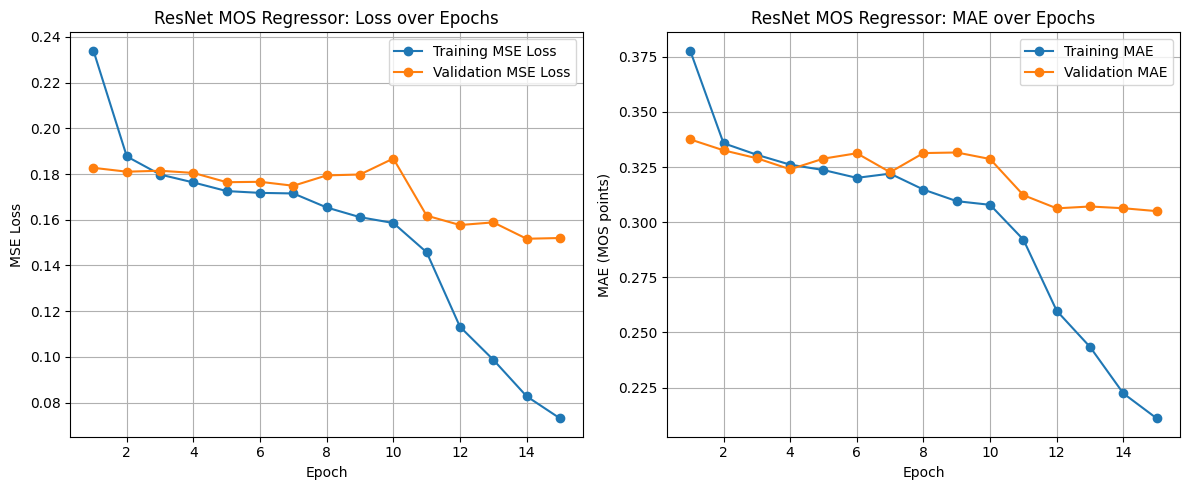

In [30]:
import matplotlib.pyplot as plt


# Number of epochs is inferred from the recorded history.
# This works whether you trained only the head or also fine-tuned the backbone,
# as long as all history lists contain the same number of entries.
epochs = range(1, len(history_resnet['train_loss']) + 1)


# 1. Plotting the Learning Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))


# --- Loss curves ---
ax1.plot(
    epochs,
    history_resnet['train_loss'],
    marker='o',
    label='Training MSE Loss',
)

ax1.plot(
    epochs,
    history_resnet['val_loss'],
    marker='o',
    label='Validation MSE Loss',
)

ax1.set_title('ResNet MOS Regressor: Loss over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('MSE Loss')
ax1.legend()
ax1.grid(True)


# --- MAE curves ---
ax2.plot(
    epochs,
    history_resnet['train_mae'],
    marker='o',
    label='Training MAE',
)

ax2.plot(
    epochs,
    history_resnet['val_mae'],
    marker='o',
    label='Validation MAE',
)

ax2.set_title('ResNet MOS Regressor: MAE over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('MAE (MOS points)')
ax2.legend()
ax2.grid(True)


plt.tight_layout()
plt.show()

## ResNet training results

| Experiment   | Phase          | Epoch | Train MSE | Train MAE | Val MSE | Val MAE |
|--------------|----------------|------:|----------:|----------:|--------:|--------:|
| ResNet 5x5   | Head training  |     1 |    0.2306 |    0.3744 |  0.1826 |  0.3398 |
| ResNet 5x5   | Head training  |     2 |    0.1914 |    0.3388 |  0.1750 |  0.3296 |
| ResNet 5x5   | Head training  |     3 |    0.1830 |    0.3318 |  0.1807 |  0.3227 |
| ResNet 5x5   | Head training  |     4 |    0.1802 |    0.3295 |  0.1835 |  0.3239 |
| ResNet 5x5   | Head training  |     5 |    0.1715 |    0.3215 |  0.1843 |  0.3281 |
| ResNet 5x5   | Fine-tuning    |     1 |    0.1560 |    0.3028 |  0.1528 |  0.3016 |
| ResNet 5x5   | Fine-tuning    |     2 |    0.1231 |    0.2701 |  0.1489 |  0.2954 |
| ResNet 5x5   | Fine-tuning    |     3 |    0.1022 |    0.2468 |  0.1479 |  0.2962 |
| ResNet 5x5   | Fine-tuning    |     4 |    0.0860 |    0.2281 |  0.1482 |  0.3011 |
| ResNet 5x5   | Fine-tuning    |     5 |    0.0778 |    0.2173 |  0.1459 |  0.2974 |
| ResNet 10x5  | Head training  |     1 |    0.2340 |    0.3778 |  0.1827 |  0.3375 |
| ResNet 10x5  | Head training  |     2 |    0.1877 |    0.3358 |  0.1810 |  0.3326 |
| ResNet 10x5  | Head training  |     3 |    0.1798 |    0.3306 |  0.1814 |  0.3290 |
| ResNet 10x5  | Head training  |     4 |    0.1763 |    0.3261 |  0.1805 |  0.3240 |
| ResNet 10x5  | Head training  |     5 |    0.1725 |    0.3237 |  0.1764 |  0.3288 |
| ResNet 10x5  | Head training  |     6 |    0.1718 |    0.3201 |  0.1766 |  0.3313 |
| ResNet 10x5  | Head training  |     7 |    0.1715 |    0.3220 |  0.1749 |  0.3227 |
| ResNet 10x5  | Head training  |     8 |    0.1654 |    0.3148 |  0.1794 |  0.3313 |
| ResNet 10x5  | Head training  |     9 |    0.1611 |    0.3095 |  0.1798 |  0.3316 |
| ResNet 10x5  | Head training  |    10 |    0.1586 |    0.3079 |  0.1868 |  0.3286 |
| ResNet 10x5  | Fine-tuning    |     1 |    0.1458 |    0.2921 |  0.1618 |  0.3123 |
| ResNet 10x5  | Fine-tuning    |     2 |    0.1132 |    0.2598 |  0.1577 |  0.3063 |
| ResNet 10x5  | Fine-tuning    |     3 |    0.0987 |    0.2434 |  0.1588 |  0.3071 |
| ResNet 10x5  | Fine-tuning    |     4 |    0.0828 |    0.2223 |  0.1517 |  0.3063 |
| ResNet 10x5  | Fine-tuning    |     5 |    0.0731 |    0.2110 |  0.1520 |  0.3050 |

## Best validation checkpoints

| Experiment  | Best phase   | Best epoch | Val MSE | Val MAE |
|-------------|--------------|-----------:|--------:|--------:|
| ResNet 5x5  | Fine-tuning  |          5 |  0.1459 |  0.2974 |
| ResNet 10x5 | Fine-tuning  |          5 |  0.1520 |  0.3050 |

## Conclusion for ResNET:

Unsurprisingly, the ResNET model was able to dish out better results (final validation MAE) than the CNN model, even with the additional tweaks and bag of tricks used below. Because ResNET is pre-trained on ImageNET dataset, meaning it is far batter at 'articulating' some of the more improtant features to extract. Our CNN model needs to learn these same features from scratch from the dataset we provided which is slim in comparison with the massive ImageNet dataset.

Overfitting was expected when using such a large model with these datasets, but in fact the task is by no means simple thus the results are logical and the current architecture that uses the ResNET for feature extraction can be said to be the best. 

Of course, with 10 epochs for head training and 5 for fine-tuning, the model took a little more time than the CNN which is expected considering its size. A small disadvantage in our current scenario and context, but which can yield exponentially larger training times with advanced tasks and bigger datasets.

## Milestone 4: Adding features to the best CNN model (Earlystopping, regularization...)

In [32]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output


class EarlyStopping:
    """
    Early stopping and checkpointing for the CNN MOS regression model.

    Monitors validation MSE loss. Saves the model whenever validation loss
    improves by at least `min_delta`, and stops training after `patience`
    consecutive non-improving epochs.
    """

    def __init__(
        self,
        patience=5,
        min_delta=0.0,
        path='best_cnn_mos_model.pth',
    ):
        """
        :param patience: Number of consecutive validation epochs without improvement
            allowed before stopping.
        :param min_delta: Minimum decrease in validation MSE required to count
            as an improvement.
        :param path: File path for the best CNN model checkpoint.
        """
        self.patience = patience
        self.min_delta = min_delta
        self.path = path

        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss, model):
        """
        Updates early-stopping state and saves the best CNN checkpoint.

        :param val_loss: Validation MSE loss for the current epoch.
        :param model: CNN model to checkpoint when validation improves.
        """
        # First validation epoch: always save the initial best model.
        if self.best_loss is None:
            self.best_loss = val_loss
            self.save_checkpoint(model)
            return

        # Improvement must be larger than min_delta.
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.save_checkpoint(model)
        else:
            self.counter += 1

            if self.counter >= self.patience:
                self.early_stop = True

    def save_checkpoint(self, model):
        """Saves the current CNN model weights to self.path."""
        torch.save(model.state_dict(), self.path)

    def load_best_model(self, model, device):
        """
        Loads the best saved CNN weights into the provided model.

        :param model: CNN model whose weights will be replaced.
        :param device: Device to which the loaded model should be moved.
        """
        model.load_state_dict(torch.load(self.path, map_location=device))
        model.to(device)
        model.eval()
        
        
def plot_grad_flow(named_parameters, ax):
    """
    Plots mean absolute gradient magnitudes for trainable CNN parameters.

    Helps identify vanishing gradients, exploding gradients, or frozen layers.
    """
    ave_grads = []
    layers = []

    for name, param in named_parameters:
        if (
            param.requires_grad
            and "bias" not in name
            and param.grad is not None
        ):
            layers.append(name)
            grad_mean = param.grad.abs().mean().item()
            ave_grads.append(grad_mean)

    ax.bar(np.arange(len(ave_grads)), ave_grads, alpha=0.5, color="teal")
    ax.set_xticks(np.arange(len(ave_grads)))
    ax.set_xticklabels(layers, rotation=45, ha="right")
    ax.set_title("CNN Gradient Flow (Mean Abs)")
    ax.set_ylabel("Gradient Magnitude")
    

def update_dashboard(history, model, val_loader, device, epoch):
    """
    Displays learning curves, CNN gradient flow, and a live MOS prediction.

    :param history: Dictionary with keys:
        'train_loss', 'val_loss', 'train_mae', 'val_mae'.
    :param model: CNN MOS regression model.
    :param val_loader: Validation DataLoader.
    :param device: CPU, CUDA, or MPS device.
    :param epoch: Current epoch number.
    """
    clear_output(wait=True)

    fig = plt.figure(figsize=(18, 5))

    # ----- 1. Learning curves -----
    ax1 = fig.add_subplot(1, 3, 1)

    ax1.plot(history['train_loss'], label='Train MSE')
    ax1.plot(history['val_loss'], label='Validation MSE')
    ax1.plot(history['train_mae'], label='Train MAE')
    ax1.plot(history['val_mae'], label='Validation MAE')

    ax1.set_title(f"Loss and MAE (Epoch {epoch})")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("MSE / MAE")
    ax1.legend()
    ax1.grid(True)

    # ----- 2. Gradient flow -----
    ax2 = fig.add_subplot(1, 3, 2)
    plot_grad_flow(model.named_parameters(), ax2)

    # ----- 3. Live sample prediction -----
    ax3 = fig.add_subplot(1, 3, 3)
    ax3.axis('off')

    model.eval()

    inputs, labels = next(iter(val_loader))
    inputs, labels = inputs.to(device), labels.to(device)

    with torch.no_grad():
        outputs = model(inputs)  # shape: [batch_size]
        predicted_mos = outputs[0].item()
        true_mos = labels[0].item()

    # Denormalize image for display.
    # Assumes normalization with mean=0.5 and std=0.5.
    img = inputs[0].cpu().permute(1, 2, 0)
    img = img * 0.5 + 0.5
    img = torch.clamp(img, 0.0, 1.0)

    ax3.imshow(img)
    ax3.set_title(
        f"Predicted MOS: {predicted_mos:.2f}\nTrue MOS: {true_mos:.2f}",
        color="green",
        weight="bold",
    )

    plt.tight_layout()
    plt.show()

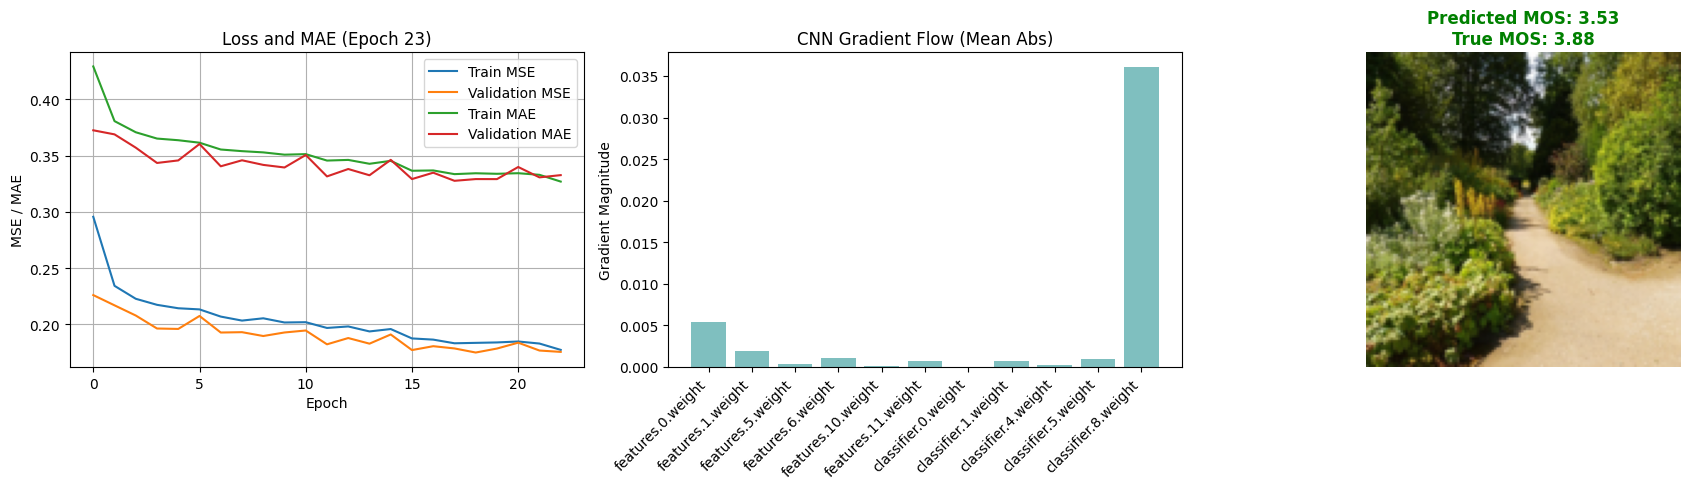

Epoch [23/30] | Train MSE: 0.1772 - MAE: 0.3268 | Val MSE: 0.1754 - MAE: 0.3326
Early stopping triggered at epoch 23.
Training finished! Loading the best weights...


CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.3, inplace=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout2d(p=0.3, inplace=False)
    (10): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Dropout2d(p=0.3, inplace=False)
  )
  (classifi

In [38]:
# 1. Initialization
ultimate_model = CNN(
    input_channels=3,          # Use 1 for grayscale images
    image_size=128,
    conv_channels=[32, 64, 128],
    hidden_sizes=[256,128],
    dropout_rate=0.3,
    score_min=1.0,
    score_max=5.0,
).to(device)

optimizer = torch.optim.Adam(ultimate_model.parameters(), lr=1e-3, weight_decay=1e-4)

# Regression loss: compares predicted MOS with true MOS
criterion = torch.nn.MSELoss()

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
)

# Initialize Early Stopping (patience of 4 epochs)
early_stopper = EarlyStopping(
    patience=7,
    min_delta=0.005,
    path='best_cnn_mos_model.pth',
)


epochs = 30
live_history = {
    'train_loss': [],
    'val_loss': [],
    'train_mae': [],
    'val_mae': [],
}


# 2. The training loop
for epoch in range(epochs):
    # Train and evaluate using the regression functions
    train_loss, train_mae = train_epoch(
        ultimate_model, train_loader, criterion, optimizer, device
    )

    val_loss, val_mae = validation(
        ultimate_model, val_loader, criterion, device
    )

    live_history['train_loss'].append(train_loss)
    live_history['val_loss'].append(val_loss)
    live_history['train_mae'].append(train_mae)
    live_history['val_mae'].append(val_mae)

    # --- UPDATE DASHBOARD ---
    update_dashboard(
        live_history,
        ultimate_model,
        val_loader,
        device,
        epoch + 1,
    )

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train MSE: {train_loss:.4f} - MAE: {train_mae:.4f} | "
        f"Val MSE: {val_loss:.4f} - MAE: {val_mae:.4f}"
    )
    
    # Reduce learning rate if validation MSE has plateaued
    scheduler.step(val_loss)

    # --- EARLY STOPPING CHECK ---
    early_stopper(val_loss, ultimate_model)

    if early_stopper.early_stop:
        print(f"Early stopping triggered at epoch {epoch + 1}.")
        break


# 3. Load the best checkpoint
print("Training finished! Loading the best weights...")

best_weights = torch.load(
    'best_cnn_mos_model.pth',
    map_location=device,
)
ultimate_model.load_state_dict(best_weights)
ultimate_model.to(device)
ultimate_model.eval()


# Final test evaluation
# final_test_loss, final_test_mae = validation(
#     ultimate_model,
#     test_loader,
#     criterion,
#     device,
# )

# final_test_rmse = final_test_loss ** 0.5

# print(
#     f"Best Test MSE: {final_test_loss:.4f} | "
#     f"Test RMSE: {final_test_rmse:.4f} | "
#     f"Test MAE: {final_test_mae:.4f}"
# )

## First run: 17 epochs early stoppage, batch size 16, no weight decay, no scheduler, patience 4, min_delta = 0.001.

### Epoch [17/30] | Train Loss:0.29 -> 0.1871 - MAE:0.45 -> 0.3370 | Val Loss:0.23 -> 0.1845 - MAE:0.38 -> 0.3438


CNN(

  (features): Sequential(

    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.3, inplace=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout2d(p=0.3, inplace=False)
    (10): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Dropout2d(p=0.3, inplace=False)

  )

  (classifier): Sequential(

    (0): Linear(in_features=32768, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=1, bias=True)
    
  )
)

# Second run: 12 Epochs (early stopped), batch size 24, weight decay at 1e-4, a scheduler to adjust the learning rate, patience 4, min_delta = 0.001.

### Epoch [12/30] | Train MSE: 0.1866 - MAE: 0.3377 | Val MSE: 0.1871 - MAE: 0.3431

CNN(

  (features): Sequential(

    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.3, inplace=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout2d(p=0.3, inplace=False)
    (10): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Dropout2d(p=0.3, inplace=False)

  )

  (classifier): Sequential(

    (0): Linear(in_features=32768, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=1, bias=True)
    
  )
)

# Third run: 12 Epochs (early stopped), batch size 24, weight decay at 1e-4, a scheduler to adjust the learning rate, patience 7, min_delta = 0.005.

Epoch [12/30] | Train MSE: 0.1908 - MAE: 0.3382 | Val MSE: 0.1884 - MAE: 0.3308

# Fourth run: 23/30 Epochs (early stopped), batch size 24, weight decay at 1e-4, a scheduler to adjust the learning rate, patience 7, min_delta = 0.005, hidden sizes [256, 128]

Epoch [23/30] | Train MSE: 0.1772 - MAE: 0.3268 | Val MSE: 0.1754 - MAE: 0.3326

## Conclusion:

In comparison, the 2 results with the scheduler and weight decay are not very different in terms of success. But what is noticeable is that it achieved the results relatively quicker, at 12 epochs rather than 17.
The third run in which larger patience and min_delta values were introduced did not yield any tangible improvement in the model's effectiveness.

So despite the loss dropping more in the first CNN model that did not use early stopping and scheduling or weight decay, validation MAE values did not witness any change.

Even on the 4th run, with additional hidden layer size, results are simply comparatively similar.
Though there were some changes in the values of training and validation loss values.

With the absence of a test dataset, real results re still somewhat ambiguous, but we can get a general understanding of the models' performance with the given architecture and design.